# Análisis Completo del Modelo de Predicción de Viento

**Objetivo:** Entrenar y analizar en profundidad un modelo que prediga si el viento será suficiente para kitesurf (`>= 18.5 km/h`), incluyendo métricas de clasificación y una visualización de las reglas del modelo.

### 1. Carga y Preparación de los Datos (Sin Fuga de Datos)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/kitesurf_calima.csv')
nudos_a_kmh = 18.52
df['Viento_Suficiente'] = (df['Viento_Vel_kmh'] >= nudos_a_kmh).astype(int)
df = pd.get_dummies(df, columns=['Condicion'], drop_first=True)
target = df['Viento_Suficiente']
features = df.drop(columns=[
    'Fecha', 
    'Hora', 
    'Viento_Dir',
    'Viento_Vel_kmh', 
    'Viento_Rafaga_kmh',
    'Viento_Suficiente'
])
print("Datos cargados y procesados.")

df.head(10)


Datos cargados y procesados.


,Temperatura_C,Precipitacion_mm,Humedad_Porc,Nubosidad_Porc,Presion_hPa,Condicion_Lluvia Fuerte,Condicion_Lluvia Ligera,Condicion_Lluvia Moderada,Condicion_Mayormente Nublado,Condicion_Nublado,Condicion_Parcialmente Nublado,Condicion_Soleado
0,21.5,0.5,85,70,1015.5,False,False,False,False,False,True,False
1,22.8,4.0,92,85,1014.8,False,False,True,False,False,False,False
2,20.1,0.7,90,80,1015.2,False,True,False,False,False,False,False
3,21.0,0.2,82,65,1016.3,False,False,False,False,False,True,False
4,22.5,2.9,88,75,1015.7,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
178,24.1,2.0,85,75,1015.8,False,True,False,False,False,False,False
179,22.0,0.0,82,70,1016.1,False,False,False,True,False,False,False
180,21.9,1.0,85,70,1015.5,False,False,False,False,False,True,False
181,23.5,4.5,90,85,1014.7,False,False,True,False,False,False,False


/var/folders/mk/dnyv3qdx2jv5qxqdq2h915j00000gp/T/ipykernel_8598/337748295.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target, palette='viridis')


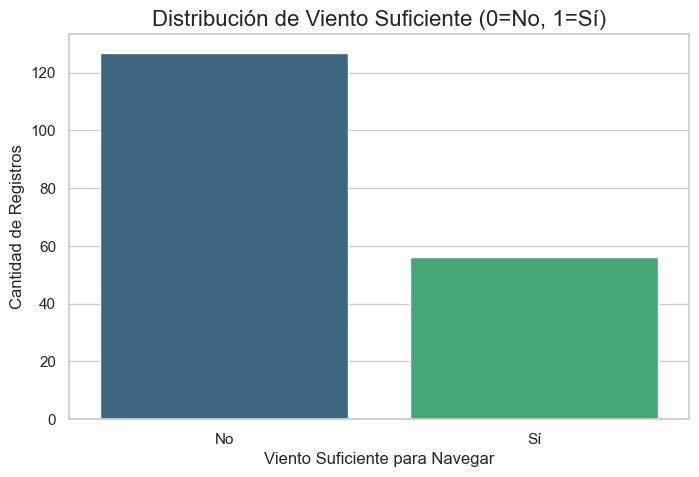

In [23]:
plt.figure(figsize=(8, 5))
sns.countplot(x=target, palette='viridis')
plt.title('Distribución de Viento Suficiente (0=No, 1=Sí)', fontsize=16)
plt.xlabel('Viento Suficiente para Navegar', fontsize=12)
plt.ylabel('Cantidad de Registros', fontsize=12)
plt.xticks([0, 1], ['No', 'Sí'])
plt.show()

### 2. División, Normalización y Entrenamiento del Modelo

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=123, stratify=target
)
    
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Entrenamos directamente el mejor modelo encontrado en el paso anterior
best_model = DecisionTreeClassifier(criterion='gini', splitter='best', max_depth=4, random_state=123)
best_model.fit(X_train_scaled, y_train)
    
# Guardamos las predicciones para usarlas en la evaluación
y_pred = best_model.predict(X_test_scaled)
    
print("Modelo entrenado y predicciones realizadas.")
X_train.describe()

Modelo entrenado y predicciones realizadas.


,Temperatura_C,Precipitacion_mm,Humedad_Porc,Nubosidad_Porc,Presion_hPa
count,146.000000,146.000000,146.000000,146.000000,146.000000
mean,22.483562,1.017808,82.102740,64.486301,1016.184247
std,1.209504,1.686771,6.821598,16.464899,1.467519
min,19.800000,0.000000,68.000000,28.000000,1012.500000
25%,21.800000,0.000000,77.000000,52.750000,1015.250000
50%,22.500000,0.000000,82.000000,65.000000,1016.300000
75%,23.275000,1.425000,88.000000,77.500000,1017.300000
max,25.200000,7.000000,95.000000,95.000000,1018.500000


### 3. Matriz de Confusión (`confusion_matrix`)

La matriz de confusión nos permite ver el rendimiento del modelo en detalle:
- **Verdaderos Positivos (VP):** El modelo predijo viento fuerte y sí hubo viento fuerte.
- **Verdaderos Negativos (VN):** El modelo predijo que no habría viento y no lo hubo.
- **Falsos Positivos (FP):** El modelo predijo viento fuerte, pero no lo hubo (error tipo I).
- **Falsos Negativos (FN):** El modelo predijo que no habría viento, pero sí lo hubo (error tipo II, el peor para un kiter).

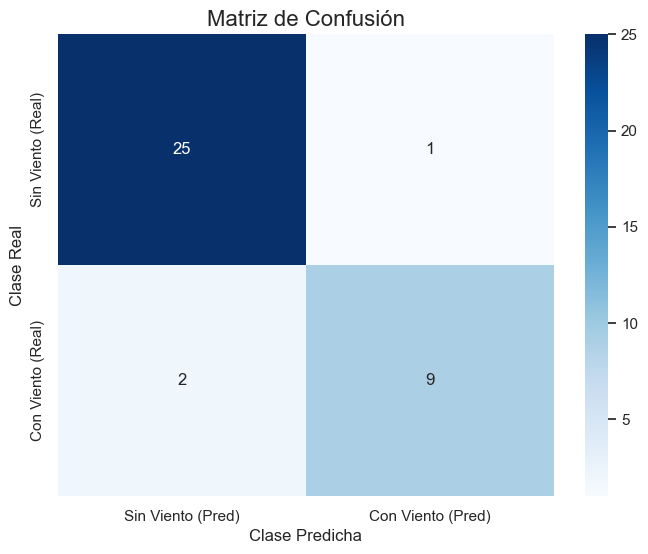

In [25]:
cm = confusion_matrix(y_test, y_pred)
    
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Sin Viento (Pred)', 'Con Viento (Pred)'], 
                yticklabels=['Sin Viento (Real)', 'Con Viento (Real)'])
plt.title('Matriz de Confusión', fontsize=16)
plt.ylabel('Clase Real', fontsize=12)
plt.xlabel('Clase Predicha', fontsize=12)
plt.show()

### 4. Reporte de Clasificación (`classification_report`)

Este reporte resume las métricas clave:
- **Precision:** De todas las veces que el modelo predijo "viento fuerte", ¿qué porcentaje fue correcto?
- **Recall (Sensibilidad):** De todos los días que realmente tuvieron "viento fuerte", ¿qué porcentaje logró identificar el modelo?
- **F1-Score:** Una media armónica de Precision y Recall, útil para clases desbalanceadas.
- **Support:** El número de muestras reales en cada clase.

In [31]:
report = classification_report(y_test, y_pred, target_names=['Sin Viento (0)', 'Con Viento (1)'])
acc = accuracy_score(y_test, y_pred)
print("Reporte de Clasificación:\n")
print(report)
print("Accuracy scoren:", acc)


Reporte de Clasificación:

                precision    recall  f1-score   support

Sin Viento (0)       0.93      0.96      0.94        26
Con Viento (1)       0.90      0.82      0.86        11

      accuracy                           0.92        37
     macro avg       0.91      0.89      0.90        37
  weighted avg       0.92      0.92      0.92        37

Accuracy scoren: 0.918918918918919


### 5. Visualización del Árbol de Decisión (`plot_tree`)

Finalmente, podemos ver el árbol exacto que el modelo construyó. Esto nos permite interpretar las reglas que está usando para hacer las predicciones. Por ejemplo: "Si `Presion_hPa` <= 0.54 y `Temperatura_C` > 0.6... entonces clasifica como viento fuerte".

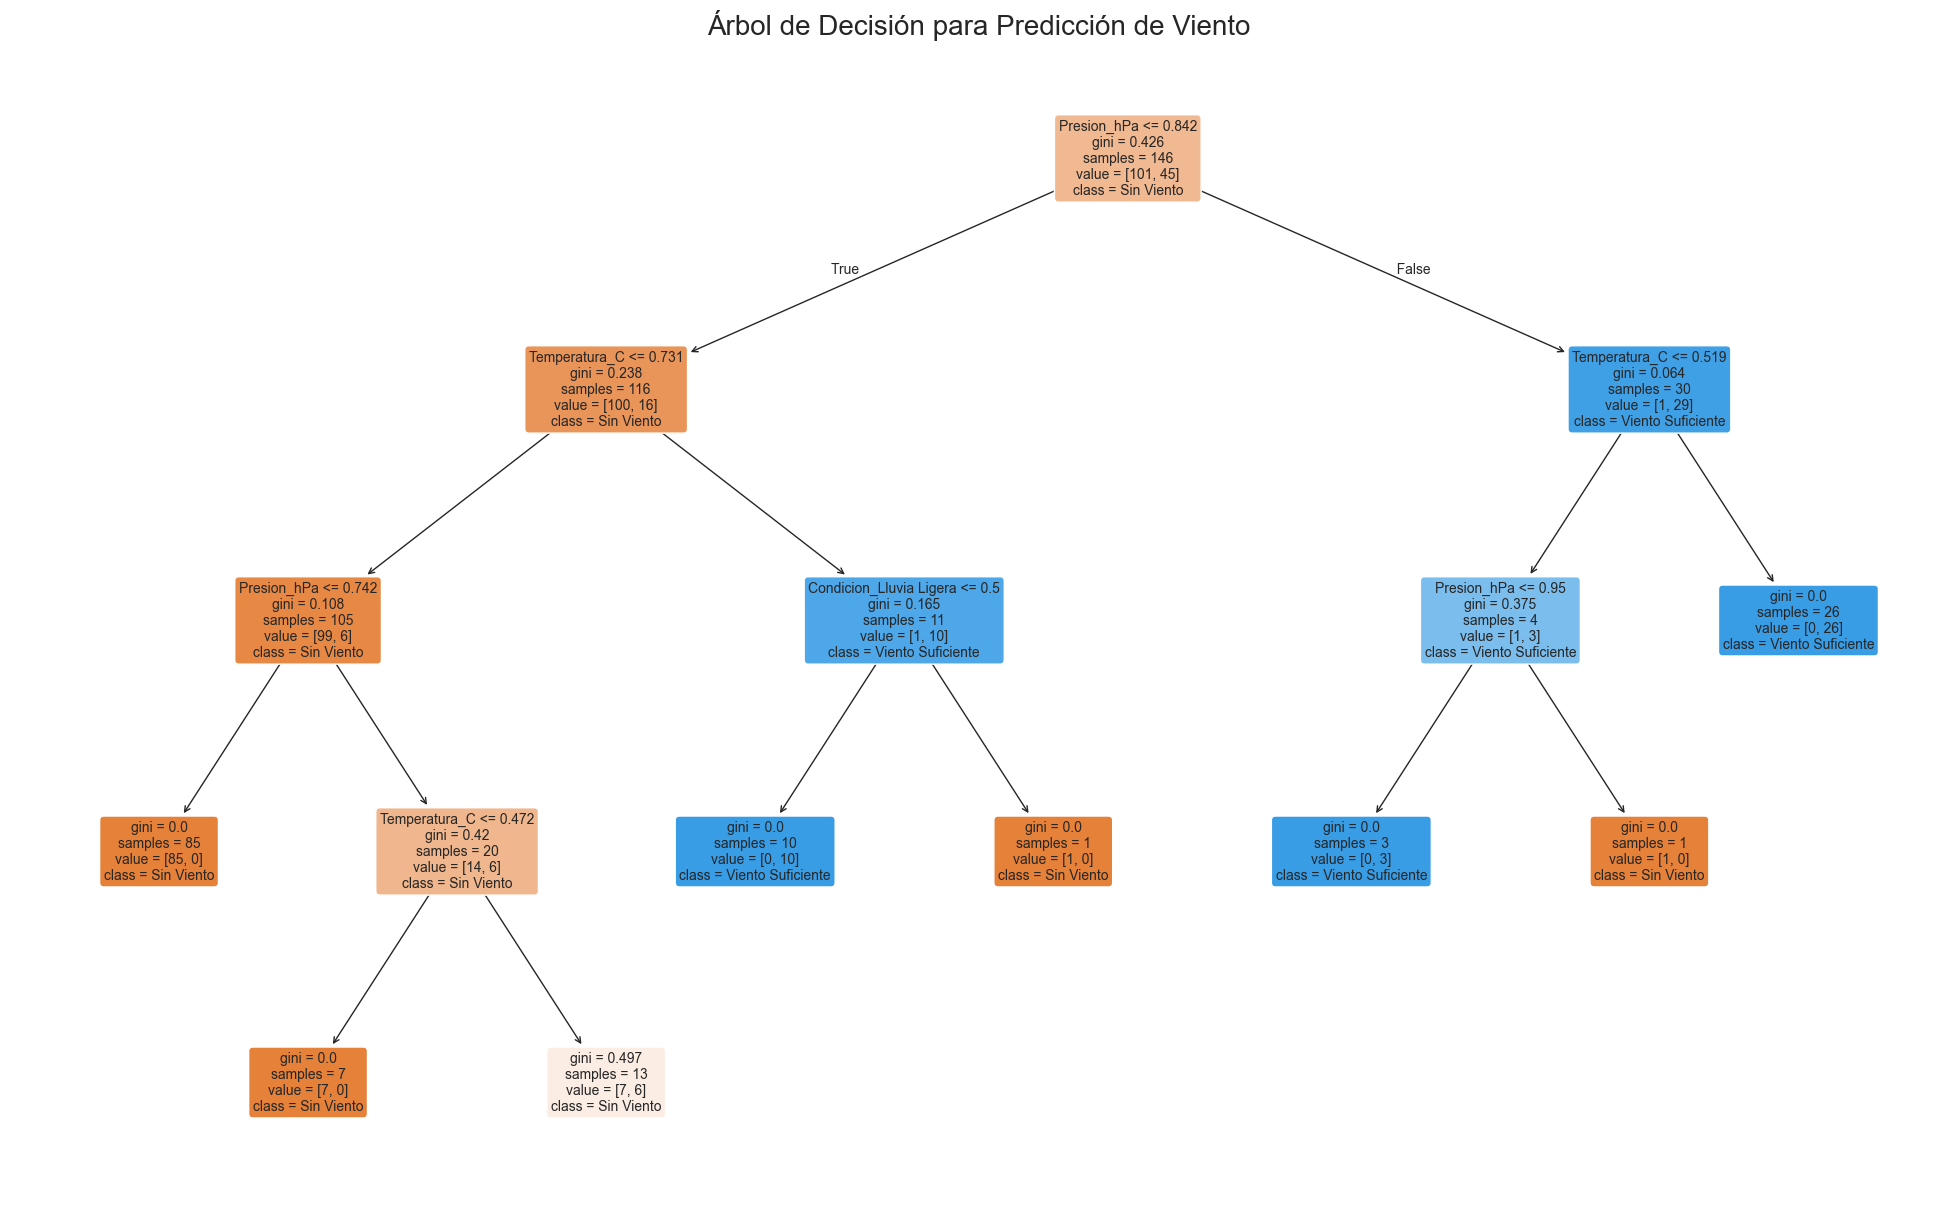

In [12]:
if not df.empty:
    plt.figure(figsize=(25, 15))
    
    plot_tree(best_model, 
              filled=True, 
              feature_names=list(features.columns),
              class_names=['Sin Viento', 'Viento Suficiente'],
              rounded=True,
              fontsize=10)
    
    plt.title("Árbol de Decisión para Predicción de Viento", fontsize=20)
    plt.show()